<a href="https://colab.research.google.com/github/ramya072006/Deep-Learning/blob/main/UNIT%202%20Lab%20Activity%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=500, n_features=20,
                           random_state=1)

X1, X2, y1, y2 = train_test_split(
    X, y, test_size=0.3, random_state=1
)

model = MLPClassifier(hidden_layer_sizes=(100, 100),
                      max_iter=500, random_state=1)

model.fit(X1, y1)

print("Training Accuracy:", accuracy_score(y1, model.predict(X1)))
print("Testing Accuracy:", accuracy_score(y2, model.predict(X2)))

Training Accuracy: 1.0
Testing Accuracy: 0.9333333333333333


In [2]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = X[:, 0]**2 + np.random.normal(0, 1, 100)

X1, X2, y1, y2 = train_test_split(
    X, y, test_size=0.25, random_state=1
)

for degree in [1, 2, 5, 10]:
    poly = PolynomialFeatures(degree)

    A = poly.fit_transform(X1)
    B = poly.transform(X2)

    model = LinearRegression()
    model.fit(A, y1)

    print("Degree:", degree)
    print("Training Error:", mean_squared_error(y1, model.predict(A)))
    print("Testing Error:", mean_squared_error(y2, model.predict(B)))

Degree: 1
Training Error: 8.749200039685016
Testing Error: 8.745109754768185
Degree: 2
Training Error: 0.9967819597809656
Testing Error: 1.0089639410978546
Degree: 5
Training Error: 0.9561656554834275
Testing Error: 0.9903038106912867
Degree: 10
Training Error: 0.9060340950492893
Testing Error: 1.11966217194746


In [3]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_squared_error

X, y = make_regression(n_samples=200, n_features=8,
                       noise=15, random_state=1)

X1, X2, y1, y2 = train_test_split(X, y, random_state=1)

for name, model in [("L1", Lasso()), ("L2", Ridge())]:
    model.fit(X1, y1)

    print(name, "Coefficients:", model.coef_)
    print(name, "Error:", mean_squared_error(y2, model.predict(X2)))

L1 Coefficients: [59.32314197 72.64082939 53.00430066 72.69426164 21.9564355  18.97731506
 24.46785489 83.56869817]
L1 Error: 367.1137900416475
L2 Coefficients: [59.78197279 73.08330695 53.54268979 73.2754654  22.84650603 20.08790061
 25.23158436 83.99168448]
L2 Error: 377.25516349720476


In [4]:
for lr in [0.001, 0.01, 0.1, 0.5]:

    w = 10.0

    for i in range(50):
        gradient = 2 * (w - 3)
        w = w - lr * gradient

    print("Learning Rate:", lr)
    print("Weight:", w)
    print("Loss:", (w - 3)**2)

Learning Rate: 0.001
Weight: 9.333227726028252
Loss: 40.10977342973298
Learning Rate: 0.01
Weight: 5.54918776060982
Loss: 6.49835823884291
Learning Rate: 0.1
Weight: 3.0000999073384897
Loss: 9.981476284104766e-09
Learning Rate: 0.5
Weight: 3.0
Loss: 0.0


In [5]:
import numpy as np

for dtype in [np.float16, np.float32, np.float64]:
    a = dtype(0.1)
    b = dtype(0.2)

    print(dtype.__name__, a + b)

float16 0.2998
float32 0.3
float64 0.30000000000000004


In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

X, y = load_breast_cancer(return_X_y=True)

model = RandomForestClassifier(random_state=1)

grid = GridSearchCV(
    model,
    {"n_estimators": [50, 100], "max_depth": [3, None]},
    cv=3
)
grid.fit(X, y)

random = RandomizedSearchCV(
    model,
    {"n_estimators": randint(50, 150), "max_depth": [3, 5, None]},
    n_iter=5, cv=3, random_state=1
)
random.fit(X, y)

print("Grid Search:", grid.best_params_)
print("Random Search:", random.best_params_)

Grid Search: {'max_depth': None, 'n_estimators': 100}
Random Search: {'max_depth': 5, 'n_estimators': 129}


In [7]:
import numpy as np

Q = np.zeros((3, 2))

for episode in range(1000):
    state = np.random.randint(3)

    for step in range(10):
        if np.random.rand() > 0.1:
            action = np.argmax(Q[state])
        else:
            action = np.random.randint(2)

        reward = (state + 1) if action == 1 else -2 * (state + 1)

        next_state = max(0, min(2, state + np.random.choice([-1, 0, 1])))

        Q[state, action] += 0.1 * (
            reward + 0.9 * np.max(Q[next_state]) - Q[state, action]
        )

        state = next_state

print("Q Table:\n", Q)
print("Best Actions:", np.argmax(Q, axis=1))

Q Table:
 [[13.93999688 17.28440763]
 [13.40541513 19.21211217]
 [13.55822646 21.70446684]]
Best Actions: [1 1 1]


In [8]:
import numpy as np
from sklearn.linear_model import Perceptron

X = np.array([[20, 600], [30, 700], [10, 400], [40, 800]])
y = np.array([1, 1, 0, 1])

model = Perceptron(max_iter=1000)
model.fit(X, y)

print("Predictions:", model.predict(X))
print("New Prediction:", model.predict([[25, 650]]))

Predictions: [1 1 1 1]
New Prediction: [1]


In [9]:
import numpy as np
from sklearn.neural_network import MLPClassifier

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])

model = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation="tanh",
    solver="lbfgs",
    max_iter=5000,
    random_state=1
)

model.fit(X, y)

print("XOR Output:", model.predict(X))

XOR Output: [0 1 1 0]


In [10]:
from sklearn.datasets import load_iris
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)

X1, X2, y1, y2 = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

model = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    max_iter=2000,
    random_state=1
)

model.fit(X1, y1)

print("Accuracy:", accuracy_score(y2, model.predict(X2)))

Accuracy: 1.0


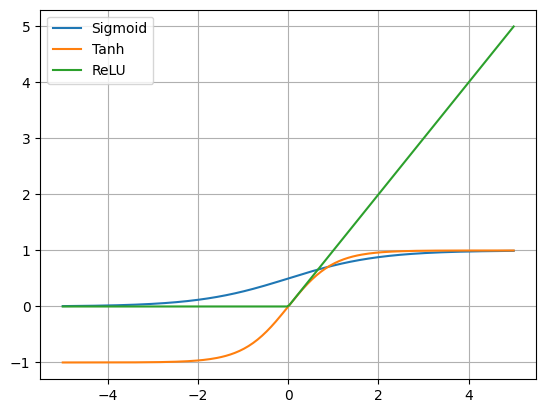

In [11]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 200)

sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, relu, label="ReLU")

plt.legend()
plt.grid()
plt.show()


In [12]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=500, n_features=10,
                           random_state=1)

X1, X2, y1, y2 = train_test_split(X, y, random_state=1)

for activation in ["relu", "logistic", "tanh"]:
    model = MLPClassifier(
        hidden_layer_sizes=(32,),
        activation=activation,
        max_iter=500,
        random_state=1
    )

    model.fit(X1, y1)

    print(activation, accuracy_score(y2, model.predict(X2)))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


relu 0.888
logistic 0.944
tanh 0.952


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [13]:
import numpy as np

X = np.array([[1.0, 2.0]])

W1 = np.array([[0.2, 0.4], [0.5, 0.3]])
b1 = np.array([0.1, 0.1])

W2 = np.array([[0.6], [0.8]])
b2 = np.array([0.2])

hidden = 1 / (1 + np.exp(-(X @ W1 + b1)))

output = 1 / (1 + np.exp(-(hidden @ W2 + b2)))

print("Hidden Layer:", hidden)
print("Output Layer:", output)

Hidden Layer: [[0.78583498 0.75026011]]
Output Layer: [[0.78103517]]


In [14]:
import numpy as np

X = np.array([[1.0, 0.5]])
target = np.array([[1.0]])

W1 = np.array([[0.1, 0.2], [0.3, 0.4]])
W2 = np.array([[0.5], [0.6]])

sigmoid = lambda x: 1 / (1 + np.exp(-x))

h = sigmoid(X @ W1)
o = sigmoid(h @ W2)

d2 = (o - target) * o * (1 - o)
d1 = (d2 @ W2.T) * h * (1 - h)

W2 -= 0.1 * h.T @ d2
W1 -= 0.1 * X.T @ d1

print("Updated W1:\n", W1)
print("Updated W2:\n", W2)

Updated W1:
 [[0.10096018 0.20112472]
 [0.30048009 0.40056236]]
Updated W2:
 [[0.50438615]
 [0.60467101]]


In [15]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

X, y = make_regression(n_samples=300, n_features=4,
                       noise=10, random_state=1)

X1, X2, y1, y2 = train_test_split(X, y, random_state=1)

model = MLPRegressor(hidden_layer_sizes=(32,),
                     max_iter=2000, random_state=1)

model.fit(X1, y1)

pred = model.predict(X2)

print("Actual:", y2[:5])
print("Predicted:", pred[:5])
print("MSE:", mean_squared_error(y2, pred))

Actual: [107.06507081 397.95045754  -2.29111232  47.20440493 204.91984134]
Predicted: [120.13800486 307.82927236  13.73448911  89.87157391 198.59088084]
MSE: 521.5427202601253


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [16]:
import numpy as np
from sklearn.metrics import log_loss, confusion_matrix

actual = np.array([0, 0, 1, 1, 0, 1])
prob = np.array([0.1, 0.2, 0.8, 0.6, 0.3, 0.9])

pred = (prob >= 0.5).astype(int)

print("Binary Cross Entropy:", log_loss(actual, prob))
print("Confusion Matrix:\n", confusion_matrix(actual, pred))

Binary Cross Entropy: 0.2540847836081325
Confusion Matrix:
 [[3 0]
 [0 3]]
